# Actividad guiada de Análisis Exploratorio de Datos (EDA)
## Selección e interpretación de visualizaciones en un caso de salud

**Asignatura:** Minería de Datos

**Estudiante:** Alean Alvarez

In [2]:
#importamos las herramientas a usar

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

pd.set_option("display.max_columns", None)

ModuleNotFoundError: No module named 'matplotlib'

In [3]:
#cargamos el dataset

rutas_posibles = [
    Path("Dataset_Sintetico_Salud_EDA.xlsx"),
    Path("outputs/actividad_eda_salud/Dataset_Sintetico_Salud_EDA.xlsx")
]

ruta_datos = next(
    (ruta for ruta in rutas_posibles if ruta.exists()),
    None
)

if ruta_datos is None:
    raise FileNotFoundError(
        "No se encontró el archivo Dataset_Sintetico_Salud_EDA.xlsx"
    )

df = pd.read_excel(
    ruta_datos,
    sheet_name="Datos"
)

df["Mes_Registro"] = pd.to_datetime(df["Mes_Registro"])

print(f"Archivo cargado: {ruta_datos}")
print(f"Dimensiones: {df.shape[0]} filas y {df.shape[1]} columnas")

df.head()

Archivo cargado: Dataset_Sintetico_Salud_EDA.xlsx
Dimensiones: 500 filas y 14 columnas


,ID_Paciente,Mes_Registro,Edad,Genero,IMC,Glucosa_mg_dL,Presion_Sistolica_mmHg,Colesterol_mg_dL,Actividad_Fisica,Fumador,Horas_Sueno,Nivel_Estres,Consultas_Medicas,Nivel_Riesgo
0,PAC-0001,2025-08-01,33,Masculino,21.6,70.0,110,149.0,Alta,No,6.5,6,0,Bajo
1,PAC-0002,2025-03-01,56,Femenino,33.8,129.0,130,171.0,Baja,No,6.8,5,0,Alto
2,PAC-0003,2025-03-01,57,Masculino,25.0,95.0,129,208.0,Moderada,Sí,5.8,8,6,Medio
3,PAC-0004,2025-11-01,68,Masculino,28.2,95.0,125,253.0,Moderada,No,7.3,6,5,Medio
4,PAC-0005,2025-02-01,47,Masculino,28.5,111.0,129,192.0,Alta,Sí,6.8,7,0,Medio


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   ID_Paciente             500 non-null    object        
 1   Mes_Registro            500 non-null    datetime64[ns]
 2   Edad                    500 non-null    int64         
 3   Genero                  500 non-null    object        
 4   IMC                     495 non-null    float64       
 5   Glucosa_mg_dL           494 non-null    float64       
 6   Presion_Sistolica_mmHg  500 non-null    int64         
 7   Colesterol_mg_dL        497 non-null    float64       
 8   Actividad_Fisica        496 non-null    object        
 9   Fumador                 500 non-null    object        
 10  Horas_Sueno             493 non-null    float64       
 11  Nivel_Estres            500 non-null    int64         
 12  Consultas_Medicas       500 non-null    int64     

In [5]:
columnas_numericas = df.select_dtypes(include="number").columns.tolist()

columnas_categoricas = (
    df.select_dtypes(include="object")
      .columns
      .drop("ID_Paciente")
      .tolist()
)

columnas_temporales = (
    df.select_dtypes(include=["datetime", "datetimetz"])
      .columns
      .tolist()
)

print("Variables numéricas:")
print(columnas_numericas)

print("\nVariables categóricas:")
print(columnas_categoricas)

print("\nVariables temporales:")
print(columnas_temporales)

Variables numéricas:
['Edad', 'IMC', 'Glucosa_mg_dL', 'Presion_Sistolica_mmHg', 'Colesterol_mg_dL', 'Horas_Sueno', 'Nivel_Estres', 'Consultas_Medicas']

Variables categóricas:
['Genero', 'Actividad_Fisica', 'Fumador', 'Nivel_Riesgo']

Variables temporales:
['Mes_Registro']


In [6]:
# Revisamos valores nulos
print("Valores nulos por columna:")
print(df.isna().sum())

print("\nPorcentaje de valores nulos:")
print((df.isna().mean() * 100).round(2))

# Revisamos valores duplicados
print("\nRegistros duplicados exactos:")
print(df.duplicated().sum())

print("\nIDs de pacientes duplicados:")
print(df["ID_Paciente"].duplicated().sum())

Valores nulos por columna:
ID_Paciente               0
Mes_Registro              0
Edad                      0
Genero                    0
IMC                       5
Glucosa_mg_dL             6
Presion_Sistolica_mmHg    0
Colesterol_mg_dL          3
Actividad_Fisica          4
Fumador                   0
Horas_Sueno               7
Nivel_Estres              0
Consultas_Medicas         0
Nivel_Riesgo              0
dtype: int64

Porcentaje de valores nulos:
ID_Paciente               0.0
Mes_Registro              0.0
Edad                      0.0
Genero                    0.0
IMC                       1.0
Glucosa_mg_dL             1.2
Presion_Sistolica_mmHg    0.0
Colesterol_mg_dL          0.6
Actividad_Fisica          0.8
Fumador                   0.0
Horas_Sueno               1.4
Nivel_Estres              0.0
Consultas_Medicas         0.0
Nivel_Riesgo              0.0
dtype: float64

Registros duplicados exactos:
3

IDs de pacientes duplicados:
3


In [7]:
#detectamos valores atipicos

def resumen_outliers_iqr(dataframe, columnas):
    resultados = []

    for columna in columnas:
        serie = dataframe[columna].dropna()

        q1 = serie.quantile(0.25)
        q3 = serie.quantile(0.75)
        iqr = q3 - q1

        limite_inferior = q1 - 1.5 * iqr
        limite_superior = q3 + 1.5 * iqr

        cantidad = (
            (serie < limite_inferior) |
            (serie > limite_superior)
        ).sum()

        resultados.append({
            "variable": columna,
            "Q1": round(q1, 2),
            "Q3": round(q3, 2),
            "IQR": round(iqr, 2),
            "limite_inferior": round(limite_inferior, 2),
            "limite_superior": round(limite_superior, 2),
            "posibles_outliers": int(cantidad)
        })

    return pd.DataFrame(resultados).sort_values(
        "posibles_outliers",
        ascending=False
    )


variables_clinicas = [
    "Edad",
    "IMC",
    "Glucosa_mg_dL",
    "Presion_Sistolica_mmHg",
    "Colesterol_mg_dL",
    "Horas_Sueno",
    "Nivel_Estres",
    "Consultas_Medicas"
]

resumen_outliers_iqr(df, variables_clinicas)

,variable,Q1,Q3,IQR,limite_inferior,limite_superior,posibles_outliers
5,Horas_Sueno,6.40,7.6,1.20,4.60,9.40,9
2,Glucosa_mg_dL,93.00,114.0,21.00,61.50,145.50,7
3,Presion_Sistolica_mmHg,114.00,132.0,18.00,87.00,159.00,6
1,IMC,24.05,30.2,6.15,14.83,39.42,4
7,Consultas_Medicas,1.00,4.0,3.00,-3.50,8.50,1
0,Edad,37.00,58.0,21.00,5.50,89.50,0
4,Colesterol_mg_dL,166.00,212.0,46.00,97.00,281.00,0
6,Nivel_Estres,4.00,7.0,3.00,-0.50,11.50,0


In [8]:
df[variables_clinicas].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Edad,500.0,47.62,15.18,18.0,37.00,47.0,58.0,85.0
IMC,495.0,27.21,4.80,17.0,24.05,26.8,30.2,58.2
Glucosa_mg_dL,494.0,104.71,24.55,62.0,93.00,103.0,114.0,336.0
Presion_Sistolica_mmHg,500.0,123.33,14.70,85.0,114.00,122.0,132.0,226.0
Colesterol_mg_dL,497.0,189.16,29.83,115.0,166.00,190.0,212.0,266.0
Horas_Sueno,493.0,7.00,0.96,3.8,6.40,7.1,7.6,9.8
Nivel_Estres,500.0,5.57,2.02,1.0,4.00,5.0,7.0,10.0
Consultas_Medicas,500.0,2.64,1.70,0.0,1.00,3.0,4.0,9.0


In [9]:
df[columnas_categoricas].describe().T

,count,unique,top,freq
Genero,500,3,Femenino,264
Actividad_Fisica,496,3,Moderada,214
Fumador,500,2,No,388
Nivel_Riesgo,500,3,Medio,196


## CASO 1

**¿Cuál categoría de actividad física es más frecuente?**

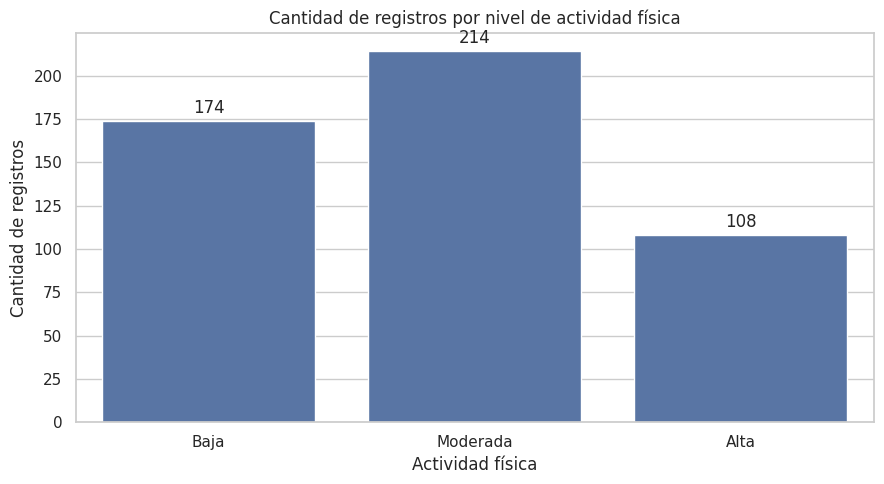

In [10]:
ax = sns.countplot(
    data=df,
    x="Actividad_Fisica",
    order=["Baja", "Moderada", "Alta"]
)

ax.set(
    title="Cantidad de registros por nivel de actividad física",
    xlabel="Actividad física",
    ylabel="Cantidad de registros"
)

for contenedor in ax.containers:
    ax.bar_label(contenedor, padding=3)

plt.tight_layout()
plt.show()

In [11]:
df["Actividad_Fisica"].value_counts(dropna=False)

,count
Actividad_Fisica,
Moderada,214
Baja,174
Alta,108
NaN,4



El gráfico permite comparar la cantidad de registros pertenecientes a cada nivel de actividad física. La categoría más frecuente es Moderada, seguida de Baja y Alta.

Se utiliza un gráfico de barras porque `Actividad_Fisica` es una variable categórica y el objetivo es comparar frecuencias entre categorías.

## CASO 2

**¿Cómo se distribuyen las horas de sueño de los pacientes?**

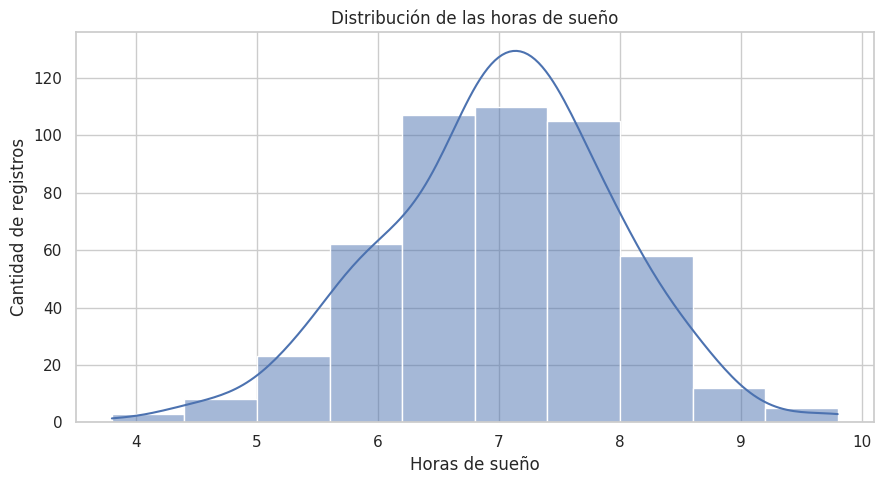

In [12]:
ax = sns.histplot(
    data=df,
    x="Horas_Sueno",
    bins=10,
    kde=True
)

ax.set(
    title="Distribución de las horas de sueño",
    xlabel="Horas de sueño",
    ylabel="Cantidad de registros"
)

plt.tight_layout()
plt.show()


El histograma permite observar cómo se distribuyen las horas de sueño de los pacientes. La mayor concentración de registros se encuentra alrededor de los valores centrales de la distribución, mientras que los valores más alejados representan una menor cantidad de observaciones.

La visualización también permite identificar posibles valores extremos que posteriormente pueden ser revisados junto con los resultados obtenidos mediante el método IQR.


## CASO 3

**¿Existen posibles valores atípicos en las variables numéricas de salud?**

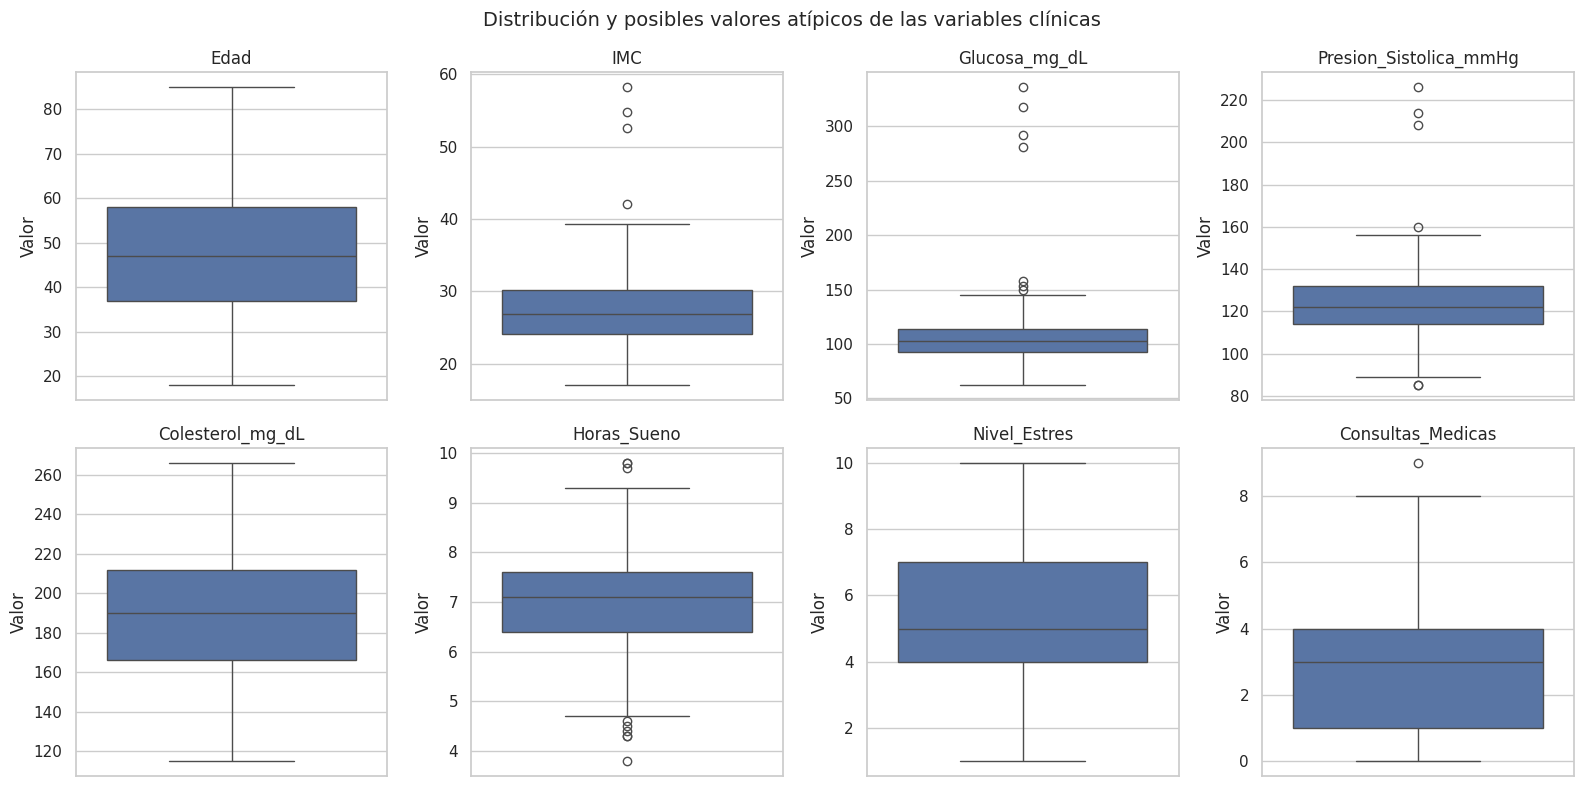

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, variable in zip(axes.flatten(), variables_clinicas):
    sns.boxplot(
        data=df,
        y=variable,
        ax=ax
    )

    ax.set_title(variable)
    ax.set_xlabel("")
    ax.set_ylabel("Valor")

plt.suptitle(
    "Distribución y posibles valores atípicos de las variables clínicas",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [14]:
outliers = resumen_outliers_iqr(df, variables_clinicas)

outliers[outliers["posibles_outliers"] > 0]

,variable,Q1,Q3,IQR,limite_inferior,limite_superior,posibles_outliers
5,Horas_Sueno,6.40,7.6,1.20,4.60,9.40,9
2,Glucosa_mg_dL,93.00,114.0,21.00,61.50,145.50,7
3,Presion_Sistolica_mmHg,114.00,132.0,18.00,87.00,159.00,6
1,IMC,24.05,30.2,6.15,14.83,39.42,4
7,Consultas_Medicas,1.00,4.0,3.00,-3.50,8.50,1



Los diagramas de caja nos permiten identificar posibles valores atípicos en algunas variables clínicas, estos resultados coinciden con la detección realizada mediante el método IQR.

La presencia de un valor atípico no implica necesariamente que exista un error en los datos. .


## CASO 4

**¿Cómo se relacionan las horas de sueño con el nivel de riesgo?**

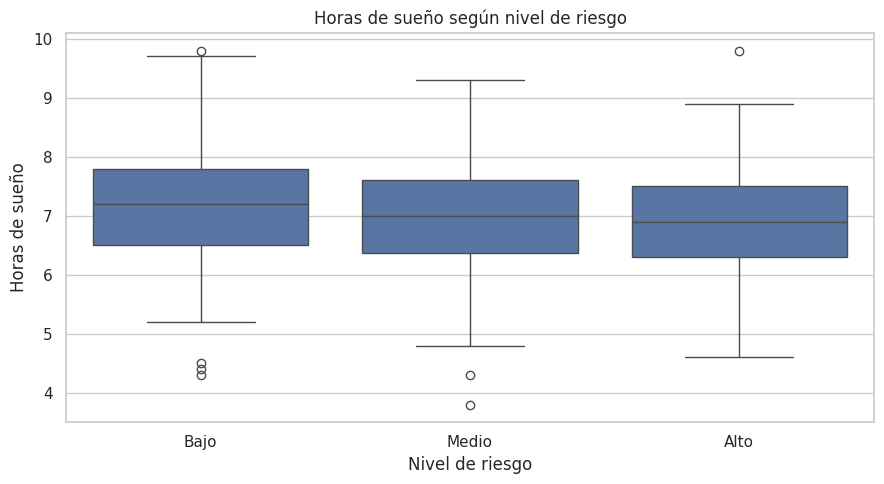

In [15]:
ax = sns.boxplot(
    data=df,
    x="Nivel_Riesgo",
    y="Horas_Sueno",
    order=["Bajo", "Medio", "Alto"]
)

ax.set(
    title="Horas de sueño según nivel de riesgo",
    xlabel="Nivel de riesgo",
    ylabel="Horas de sueño"
)

plt.tight_layout()
plt.show()

In [16]:
df.groupby("Nivel_Riesgo")["Horas_Sueno"].median().reindex(
    ["Bajo", "Medio", "Alto"]
)

,Horas_Sueno
Nivel_Riesgo,
Bajo,7.2
Medio,7.0
Alto,6.9



El boxplot nos permite comparar la distribución de las horas de sueño entre los diferentes niveles de riesgo, podemos observar diferencias en la distribución y en las medianas entre los grupos.


## CASO 5

**¿Cómo se distribuye el nivel de riesgo según la actividad física?**

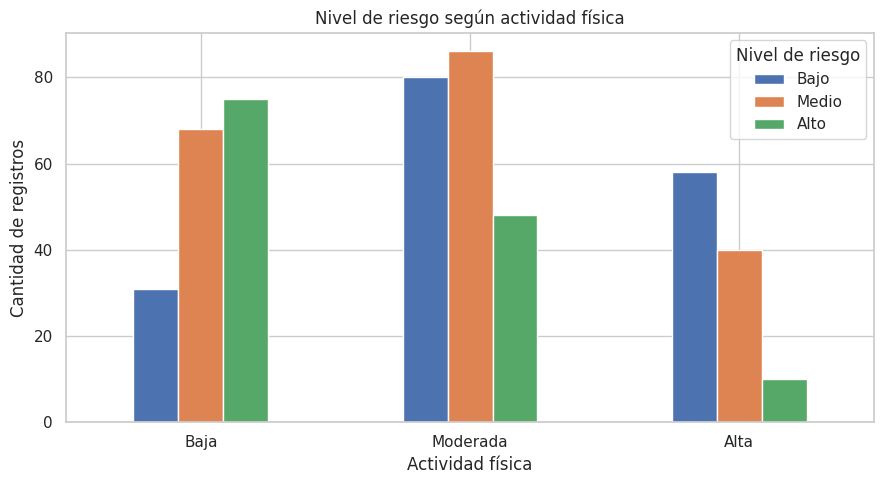

In [17]:
tabla_riesgo_actividad = pd.crosstab(
    df["Actividad_Fisica"],
    df["Nivel_Riesgo"]
).reindex(
    index=["Baja", "Moderada", "Alta"],
    columns=["Bajo", "Medio", "Alto"],
    fill_value=0
)

ax = tabla_riesgo_actividad.plot(
    kind="bar",
    figsize=(9, 5)
)

ax.set(
    title="Nivel de riesgo según actividad física",
    xlabel="Actividad física",
    ylabel="Cantidad de registros"
)

plt.xticks(rotation=0)
plt.legend(title="Nivel de riesgo")
plt.tight_layout()
plt.show()

In [18]:
tabla_porcentajes = pd.crosstab(
    df["Actividad_Fisica"],
    df["Nivel_Riesgo"],
    normalize="index"
) * 100

tabla_porcentajes = tabla_porcentajes.reindex(
    index=["Baja", "Moderada", "Alta"],
    columns=["Bajo", "Medio", "Alto"]
)

tabla_porcentajes.round(2)

Nivel_Riesgo,Bajo,Medio,Alto
Actividad_Fisica,,,
Baja,17.82,39.08,43.10
Moderada,37.38,40.19,22.43
Alta,53.70,37.04,9.26



El gráfico nos permite comparar la distribución de los niveles de riesgo entre las diferentes categorías de actividad física, La tabla de porcentajes facilita la comparación entre grupos con diferentes cantidades de registros.

Los resultados permiten identificar diferencias descriptivas entre los niveles de actividad física y riesgo.


## CASO 6

**¿Existe alguna relación entre la edad y la presión sistólica?**

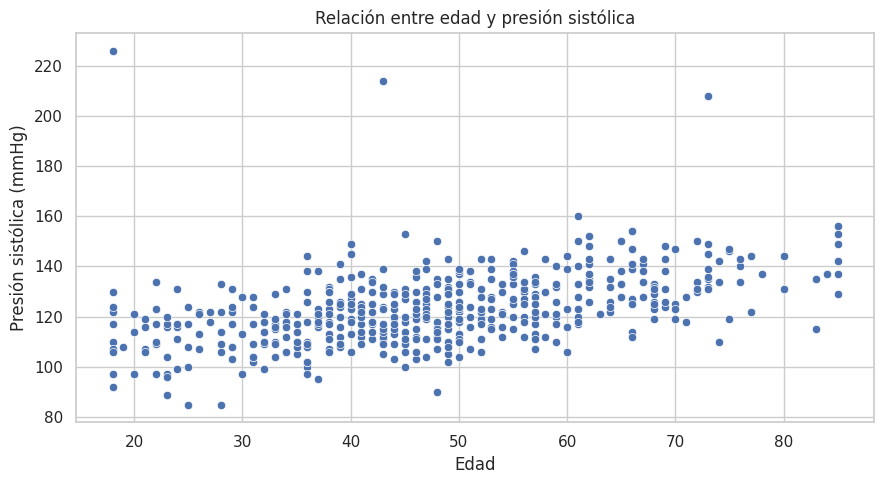

In [19]:
ax = sns.scatterplot(
    data=df,
    x="Edad",
    y="Presion_Sistolica_mmHg"
)

ax.set(
    title="Relación entre edad y presión sistólica",
    xlabel="Edad",
    ylabel="Presión sistólica (mmHg)"
)

plt.tight_layout()
plt.show()

In [20]:
correlacion = df[["Edad", "Presion_Sistolica_mmHg"]].corr().iloc[0, 1]

print(f"Correlación entre edad y presión sistólica: {correlacion:.2f}")

Correlación entre edad y presión sistólica: 0.46



El gráfico de dispersión permitió observar la relación entre la edad y la presión sistólica, Los puntos muestran cómo se distribuyen los valores de presión para diferentes edades.

El coeficiente de correlación complementa la visualización proporcionando una medida numérica de la relación lineal entre ambas variables. Este resultado debe interpretarse como una asociación entre las variables y no como una relación causal.


## CASO 7

**¿Qué relaciones lineales se observan entre las principales variables numéricas del dataset?**

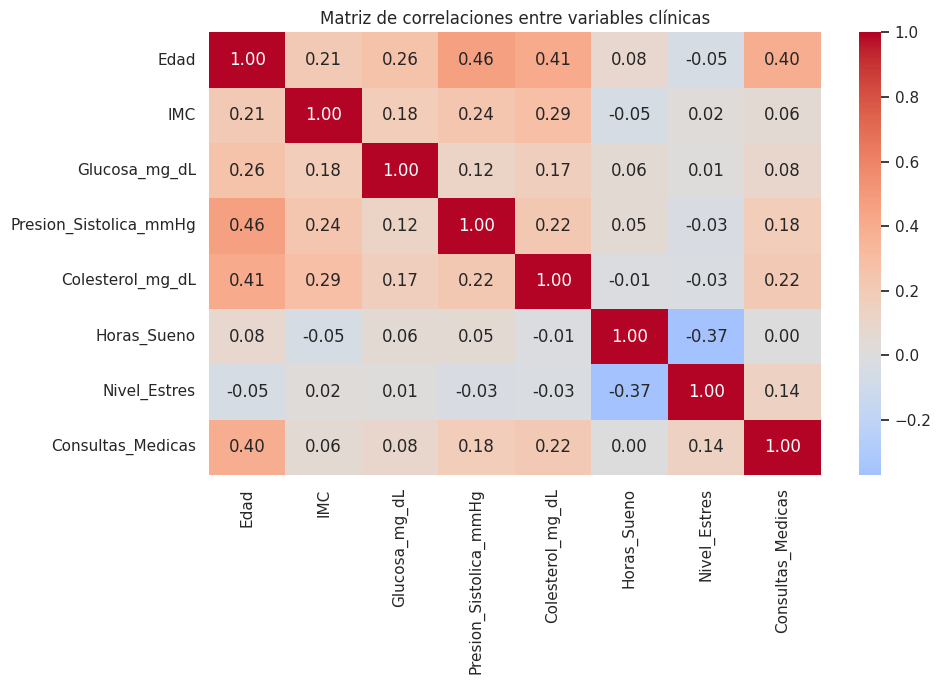

In [21]:
matriz_correlacion = df[variables_clinicas].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    matriz_correlacion,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Matriz de correlaciones entre variables clínicas")
plt.tight_layout()
plt.show()

In [22]:
correlaciones = (
    matriz_correlacion
    .where(np.triu(np.ones(matriz_correlacion.shape), k=1).astype(bool))
    .stack()
    .sort_values(key=lambda x: x.abs(), ascending=False)
)

correlaciones.head(10)

Edad                    Presion_Sistolica_mmHg    0.464309
                        Colesterol_mg_dL          0.408436
                        Consultas_Medicas         0.396299
Horas_Sueno             Nivel_Estres             -0.370582
IMC                     Colesterol_mg_dL          0.286451
Edad                    Glucosa_mg_dL             0.259713
IMC                     Presion_Sistolica_mmHg    0.242870
Presion_Sistolica_mmHg  Colesterol_mg_dL          0.221202
Colesterol_mg_dL        Consultas_Medicas         0.217571
Edad                    IMC                       0.214584
dtype: float64


La matriz de correlaciones permite identificar la intensidad y dirección de las relaciones lineales entre las variables numéricas. Los valores positivos indican asociaciones en la misma dirección, mientras que los valores negativos indican asociaciones en direcciones opuestas.

Las correlaciones más cercanas a cero representan relaciones lineales más débiles. Estos resultados permiten identificar posibles relaciones de interés para análisis posteriores, pero una correlación no demuestra por sí sola una relación causal.


## CASO 8

**¿Cómo cambia mensualmente el porcentaje de registros con nivel de riesgo alto?**

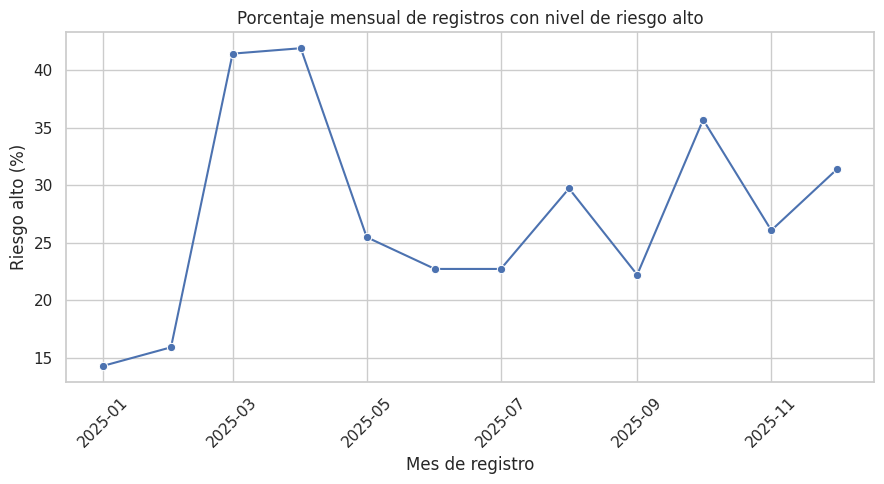

,Mes_Registro,porcentaje_alto,registros
0,2025-01-01,14.3,49
1,2025-02-01,15.9,44
2,2025-03-01,41.5,41
3,2025-04-01,41.9,31
4,2025-05-01,25.5,51
5,2025-06-01,22.7,44
6,2025-07-01,22.7,44
7,2025-08-01,29.7,37
8,2025-09-01,22.2,36
9,2025-10-01,35.7,42


In [23]:
riesgo_alto_mensual = (
    df.assign(
        Riesgo_Alto=df["Nivel_Riesgo"].eq("Alto")
    )
    .groupby("Mes_Registro", as_index=False)
    .agg(
        porcentaje_alto=("Riesgo_Alto", "mean"),
        registros=("Riesgo_Alto", "size")
    )
)

riesgo_alto_mensual["porcentaje_alto"] *= 100

ax = sns.lineplot(
    data=riesgo_alto_mensual,
    x="Mes_Registro",
    y="porcentaje_alto",
    marker="o"
)

ax.set(
    title="Porcentaje mensual de registros con nivel de riesgo alto",
    xlabel="Mes de registro",
    ylabel="Riesgo alto (%)"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

riesgo_alto_mensual.assign(
    porcentaje_alto=riesgo_alto_mensual["porcentaje_alto"].round(1)
)

El porcentaje de riesgo alto cambia entre los meses, Los valores son especialmente altos en marzo y abril, mientras que enero y febrero presentan porcentajes menores.


##CASO 9

**¿Cómo se distribuye el nivel de riesgo dentro de cada nivel de actividad física?**

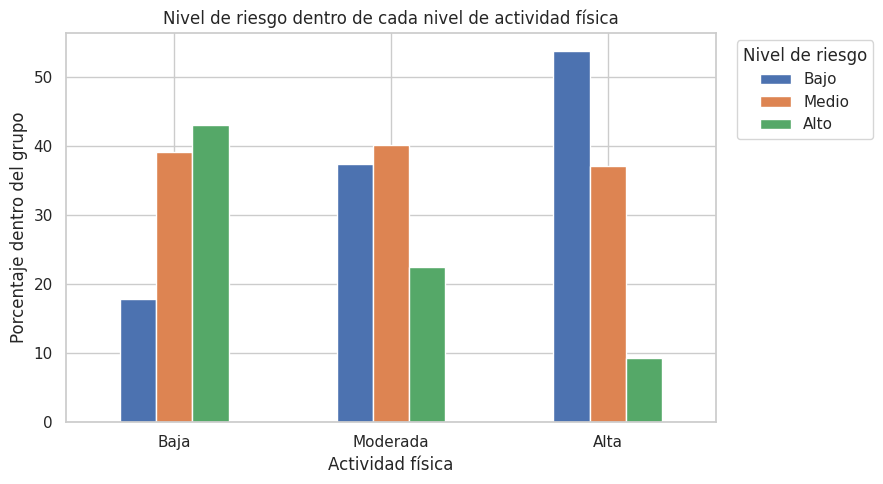

Nivel_Riesgo,Bajo,Medio,Alto
Actividad_Fisica,,,
Baja,17.8,39.1,43.1
Moderada,37.4,40.2,22.4
Alta,53.7,37.0,9.3


In [26]:
actividad_riesgo = (
    pd.crosstab(
        df["Actividad_Fisica"],
        df["Nivel_Riesgo"],
        normalize="index"
    )
    .reindex(
        index=["Baja", "Moderada", "Alta"],
        columns=["Bajo", "Medio", "Alto"]
    )
    .mul(100)
)

ax = actividad_riesgo.plot(
    kind="bar",
    figsize=(9, 5)
)

ax.set(
    title="Nivel de riesgo dentro de cada nivel de actividad física",
    xlabel="Actividad física",
    ylabel="Porcentaje dentro del grupo"
)

ax.legend(
    title="Nivel de riesgo",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

actividad_riesgo.round(1)

La composición del nivel de riesgo cambia entre los niveles de actividad física. En el dataset sintético, la actividad baja concentra una mayor proporción de riesgo alto. Por esta razón, es importante comparar proporciones y no solamente conteos ya que los grupos tienen tamaños diferentes.


## Conclusiones

1. **Histograma vs barras:** el histograma agrupa valores numéricos continuos en intervalos, las barras muestran frecuencias de categorías discretas sin continuidad entre ellas.

2. **Por qué no eliminar un outlier automáticamente:** puede ser un dato real y no un error; el método IQR solo señala casos para investigar, no ordena borrarlos.

3. **Ventaja de las proporciones:** permiten comparar grupos de tamaños distintos en igualdad de condiciones, como se hizo entre Actividad_Fisica y Nivel_Riesgo con `normalize="index"`.

4. **Qué pierde una matriz de correlación:** solo resume la fuerza y dirección lineal en un número; no muestra relaciones no lineales, subgrupos ni puntos influyentes, algo que sí se ve en un diagrama de dispersión.

5. **Evidencia necesaria para causalidad:** diseño experimental con asignación aleatoria, control de variables de confusión, temporalidad y replicación en otras muestras. Las asociaciones de este EDA son solo eso, no prueban causalidad.